# PINZAS 2 — La platina: qué se movió de verdad

En las grabaciones con la pinza prendida se movía la platina con los motores («patadas») para ver cuándo se escapaba la partícula. El cuaderno anota lo que se le pidió al motor (aceleración, paso, velocidad máxima) y a qué hora, pero **esos valores no son confiables**. Acá se mide lo que pasó usando el video:

- **cuánto se corre toda la imagen** de un cuadro al siguiente (`platina.csv`, por correlación de cuadros consecutivos: `TouchDesigner/herramientas/platina.py`). La trampa está fija en la imagen; lo que se corre es todo lo demás;
- se **detecta cada patada**, se mide su desplazamiento, duración y velocidad, y se la empareja con el renglón del cuaderno por la hora;
- se chequea el desplazamiento con un método independiente (las partículas seguidas antes y después).

Salidas: `datos/<grabación>/patadas.csv`, `datos/pinzas/patadas.csv` (todas juntas) y `figuras/PINZAS 2/`.
Las columnas de las tablas están documentadas en `analisis/pinzas_datos.py` y `analisis/pinzas_fuerza.py`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pinzas_datos import RAIZ, DATOS, CATALOGO, ESCALA_UM, cargar, velocidad_platina
from pinzas_fuerza import guardar_fuerza

plt.style.use("seaborn-v0_8")
fs = 14
plt.rcParams.update({"font.family": "serif", "font.size": fs, "axes.labelsize": fs,
                     "xtick.labelsize": fs, "ytick.labelsize": fs, "legend.fontsize": fs,
                     "mathtext.default": "regular", "mathtext.fontset": "cm", "legend.frameon": True})
SERIE1, SERIE2, AJUSTE = "#2A9D8F", "#E76F51", "#264653"
FIGURAS = os.path.join(RAIZ, "figuras", "PINZAS 2")
os.makedirs(FIGURAS, exist_ok=True)
os.makedirs(os.path.join(DATOS, "pinzas"), exist_ok=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURAS, nombre + ".pdf"), bbox_inches="tight")
    fig.savefig(os.path.join(FIGURAS, nombre + ".png"), bbox_inches="tight", dpi=300)


CON_PATADAS = [n for n, v in CATALOGO.items() if v["tipo"] == "patadas"]
tablas = []
for nombre in CON_PATADAS:
    _, _, p = guardar_fuerza(nombre)                    # escribe atrapada.csv, seguida.csv, fuerza_intervalos.csv y patadas.csv
    p.insert(0, "grabacion", nombre)
    tablas.append(p)
pat = pd.concat(tablas, ignore_index=True)
pat.to_csv(os.path.join(DATOS, "pinzas", "patadas.csv"), index=False, float_format="%.5g")
res = pat.groupby("grabacion", sort=False).agg(movimientos=("n", "size"), confiables=("confiable", "sum"),
                                              con_cuaderno=("n_cuaderno", "count"))
print("%d movimientos de platina detectados, %d confiables, %d emparejados con el cuaderno" % (len(pat), pat.confiable.sum(), pat.n_cuaderno.notna().sum()))
res

218 movimientos de platina detectados, 170 confiables, 31 emparejados con el cuaderno


,movimientos,confiables,con_cuaderno
grabacion,,,
LASER NE,51,50,0
BARRIDO 1,14,14,11
MUEVO A MANO,27,23,0
BARRIDO 2,23,15,2
BARRIDO STEPSIZE,24,17,6
BARRIDO STEPSIZE 2,13,11,12
BARRIDO STEPSIZE 3,66,40,0


## 1. ¿Se puede creer el desplazamiento medido?

Cada movimiento se mide de dos formas independientes:

- **correlación:** suma de los corrimientos cuadro a cuadro;
- **partículas:** el corrimiento más votado entre las posiciones de las partículas seguidas dos cuadros antes y dos cuadros después.

Un movimiento es **confiable** si la correlación fue buena (pico ≥ 0.2) o si las partículas confirman el desplazamiento. Los no confiables son casi todos tramos largos con la imagen cambiando (foco, movimientos muy rápidos o a mano) y no se usan.

131 movimientos con las dos medidas | diferencia: mediana 0.52 µm (15 % del desplazamiento), percentil 90 1.19 µm
no confiables: 48 de 218


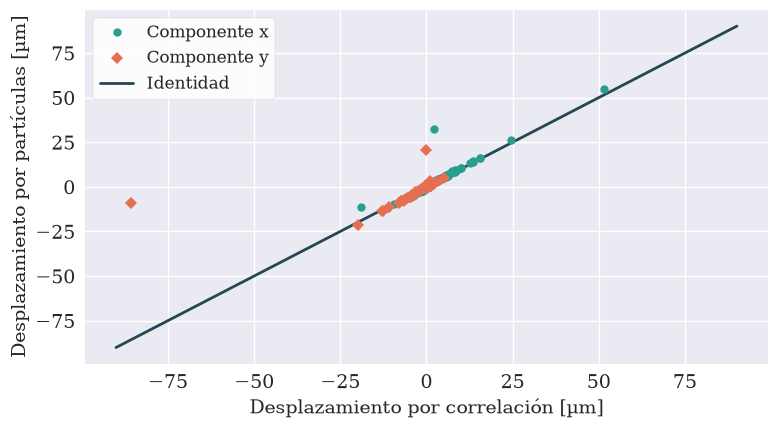

In [2]:
ok = pat[pat.confiable & pat.dx_part_um.notna()]
fig, ax = plt.subplots(figsize=(8, 4.5))
for col_c, col_p, color, fmt, nombre in (("dx_um", "dx_part_um", SERIE1, "o", "Componente $x$"), ("dy_um", "dy_part_um", SERIE2, "D", "Componente $y$")):
    ax.plot(ok[col_c], ok[col_p], fmt, ms=6, color=color, mec=color, zorder=3, label=nombre)
lim = 1.05 * np.nanmax(np.abs(ok[["dx_um", "dy_um", "dx_part_um", "dy_part_um"]].values))
ax.plot([-lim, lim], [-lim, lim], color=AJUSTE, lw=2, zorder=2, label="Identidad")
ax.set_xlabel("Desplazamiento por correlación [µm]")
ax.set_ylabel("Desplazamiento por partículas [µm]")
ax.legend(loc="upper left", fontsize=12, facecolor="white", framealpha=0.9)
guardar(fig, "validacion_desplazamiento")
dif = np.hypot(ok.dx_um - ok.dx_part_um, ok.dy_um - ok.dy_part_um)
tam = np.hypot(ok.dx_um, ok.dy_um)
print("%d movimientos con las dos medidas | diferencia: mediana %.2f µm (%.0f %% del desplazamiento), percentil 90 %.2f µm"
      % (len(ok), dif.median(), 100 * (dif / tam).median(), dif.quantile(0.9)))
print("no confiables: %d de %d" % ((~pat.confiable).sum(), len(pat)))

## 2. Las patadas del cuaderno

Cada renglón del cuaderno con hora se empareja con el movimiento detectado más cercano en el tiempo (a menos de 4 s). `resultado` es lo que hizo la partícula según el video (ver PINZAS 3); `resultado_cuaderno` es lo anotado.

In [3]:
cu = pat[pat.n_cuaderno.notna()].copy()
cu["dif_t_s"] = cu.t_ini_s - cu.t_cuaderno_s
cu["desplazamiento_um"] = np.hypot(cu.dx_um, cu.dy_um)
print("diferencia de hora video − cuaderno: mediana %+.2f s, entre %+.1f y %+.1f s" % (cu.dif_t_s.median(), cu.dif_t_s.min(), cu.dif_t_s.max()))
faltan = pd.read_csv(os.path.join(DATOS, "cuaderno", "patadas_cuaderno.csv"))
faltan = faltan[faltan.t_cuaderno_s.notna()].merge(cu[["grabacion", "n_cuaderno"]], how="left", left_on=["grabacion", "n"],
                                                  right_on=["grabacion", "n_cuaderno"])
faltan = faltan[faltan.n_cuaderno.isna()]
print("renglones del cuaderno SIN movimiento en el video:", ", ".join("%s n=%d (t=%.0f s)" % (r.grabacion, r.n, r.t_cuaderno_s) for r in faltan.itertuples()) or "ninguno")
cu[["grabacion", "n_cuaderno", "t_cuaderno_s", "t_ini_s", "a_nominal_um_s2", "paso_nominal_um", "desplazamiento_um", "duracion_s",
    "v_pico_um_s", "resultado", "resultado_cuaderno"]].round(2)

diferencia de hora video − cuaderno: mediana -0.15 s, entre -2.6 y +0.2 s
renglones del cuaderno SIN movimiento en el video: BARRIDO 1 n=1 (t=0 s), BARRIDO 1 n=2 (t=19 s), BARRIDO 1 n=3 (t=42 s), BARRIDO 1 n=7 (t=140 s), BARRIDO 2 n=2 (t=84 s), BARRIDO STEPSIZE n=3 (t=99 s), BARRIDO STEPSIZE 2 n=10 (t=190 s)


,grabacion,n_cuaderno,t_cuaderno_s,t_ini_s,a_nominal_um_s2,paso_nominal_um,desplazamiento_um,duracion_s,v_pico_um_s,resultado,resultado_cuaderno
51,BARRIDO 1,4.0,62.61,62.57,400.0,100.0,10.02,0.40,39.79,escapo,escapo
52,BARRIDO 1,5.0,86.93,86.82,350.0,100.0,6.51,0.30,27.95,se aparto y volvio,atrapada
53,BARRIDO 1,6.0,115.99,115.96,350.0,100.0,12.70,0.40,47.46,escapo,escapo
56,BARRIDO 1,8.0,146.06,146.09,350.0,100.0,4.38,0.30,20.51,se aparto y volvio,atrapada
57,BARRIDO 1,9.0,208.66,208.76,380.0,100.0,5.36,0.30,25.80,escapo,escapo
58,BARRIDO 1,10.0,219.18,219.04,380.0,100.0,7.10,0.40,31.90,se aparto y volvio,atrapada
59,BARRIDO 1,11.0,230.76,230.72,380.0,100.0,4.70,0.30,20.00,se aparto y volvio,atrapada
60,BARRIDO 1,12.0,251.09,251.17,400.0,100.0,5.09,0.30,23.30,se aparto y volvio,atrapada
61,BARRIDO 1,13.0,263.69,263.75,400.0,100.0,4.71,0.20,23.62,se aparto y volvio,atrapada
62,BARRIDO 1,14.0,279.09,279.11,420.0,100.0,6.84,0.30,31.43,se aparto y volvio,escapo


desplazamiento medido / paso pedido: mediana 0.054, entre 0.019 y 0.616
correlación (Spearman) entre paso pedido y desplazamiento medido: -0.22


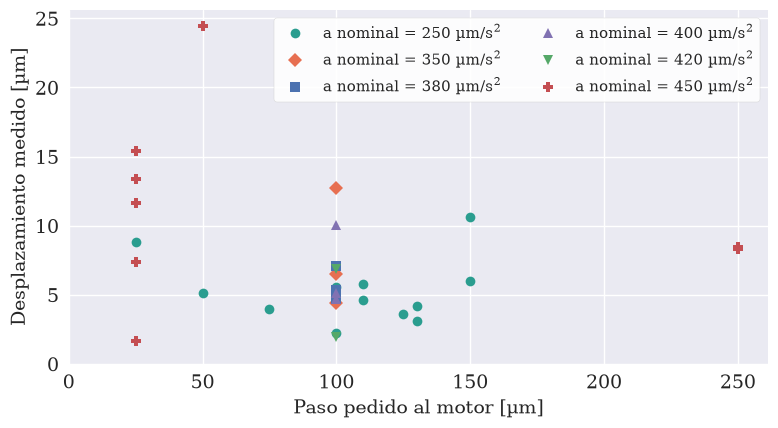

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for (a_nom, g), color, fmt in zip(cu.groupby("a_nominal_um_s2"), (SERIE1, SERIE2, "#4C72B0", "#8172B2", "#55A868", "#C44E52", "#CCB974", "#64B5CD"), "oDs^vP*X"):
    ax.plot(g.paso_nominal_um, g.desplazamiento_um, fmt, ms=7, color=color, mec=color, zorder=3, label=r"$a$ nominal = %g µm/s$^2$" % a_nom)
ax.set_xlabel("Paso pedido al motor [µm]")
ax.set_ylabel("Desplazamiento medido [µm]")
ax.set_xlim(0, None); ax.set_ylim(0, None)
ax.legend(loc="upper right", fontsize=11, ncol=2, facecolor="white", framealpha=0.9)
guardar(fig, "paso_nominal_vs_medido")
print("desplazamiento medido / paso pedido: mediana %.3f, entre %.3f y %.3f" % ((cu.desplazamiento_um / cu.paso_nominal_um).median(),
      (cu.desplazamiento_um / cu.paso_nominal_um).min(), (cu.desplazamiento_um / cu.paso_nominal_um).max()))
print("correlación (Spearman) entre paso pedido y desplazamiento medido: %.2f" % cu[["paso_nominal_um", "desplazamiento_um"]].corr(method="spearman").iloc[0, 1])

## 3. Cómo es una patada en el tiempo

Velocidad de la imagen cuadro a cuadro (corrimiento dividido el tiempo entre cuadros) de las patadas emparejadas con el cuaderno, alineadas en su máximo. **La patada entera dura 2 a 5 cuadros**: es el límite principal de todo lo que sigue, porque cada valor es un promedio sobre 0.08 a 0.1 s de un movimiento que dura 0.2 a 0.5 s.

duración: mediana 0.32 s (2 a 6 cuadros) | desplazamiento: mediana 5.7 µm (de 1.7 a 24.5) | velocidad pico por cuadro: mediana 27 µm/s (de 9 a 92)


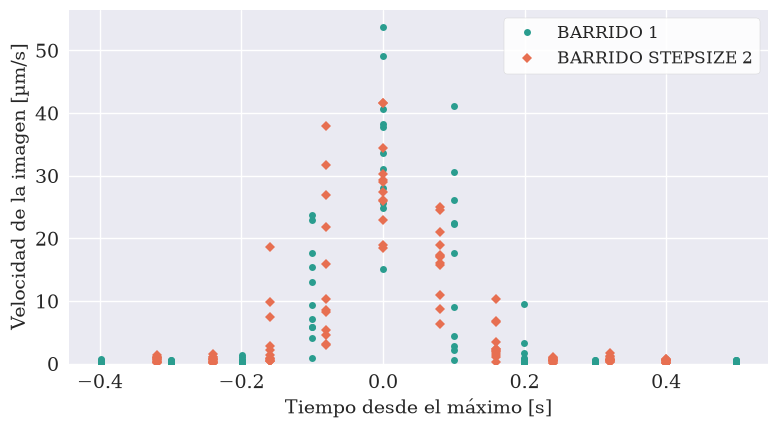

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre, color, fmt in (("BARRIDO 1", SERIE1, "o"), ("BARRIDO STEPSIZE 2", SERIE2, "D")):
    pl = cargar(nombre)["platina"]
    dt = np.median(np.diff(pl.t_s))
    v = np.hypot(pl.dx_px, pl.dy_px).values * ESCALA_UM / dt
    primera = True
    for r in cu[cu.grabacion == nombre].itertuples():
        k = r.cuadro_ini + int(np.argmax(v[r.cuadro_ini:r.cuadro_fin + 1]))
        i = np.arange(k - 4, k + 6)
        ax.plot((i - k) * dt, v[i], fmt, ms=5, color=color, mec=color, zorder=3, label=nombre if primera else None)
        primera = False
ax.set_xlabel("Tiempo desde el máximo [s]")
ax.set_ylabel("Velocidad de la imagen [µm/s]")
ax.set_ylim(0, None)
ax.legend(loc="upper right", fontsize=12, facecolor="white", framealpha=0.9)
guardar(fig, "perfil_de_las_patadas")
print("duración: mediana %.2f s (%d a %d cuadros) | desplazamiento: mediana %.1f µm (de %.1f a %.1f) | velocidad pico por cuadro: mediana %.0f µm/s (de %.0f a %.0f)"
      % (cu.duracion_s.median(), (cu.cuadro_fin - cu.cuadro_ini + 1).min(), (cu.cuadro_fin - cu.cuadro_ini + 1).max(),
         cu.desplazamiento_um.median(), cu.desplazamiento_um.min(), cu.desplazamiento_um.max(),
         cu.v_pico_um_s.median(), cu.v_pico_um_s.min(), cu.v_pico_um_s.max()))

## 4. Todos los movimientos, por grabación

Además de las patadas del cuaderno hay movimientos que no están anotados: correcciones a mano para volver a buscar la partícula, la grabación `MUEVO A MANO`, y en `LASER NE` una deriva lenta y continua de toda la muestra.

In [6]:
for nombre in CON_PATADAS:
    g = pat[(pat.grabacion == nombre) & pat.confiable]
    d = np.hypot(g.dx_um, g.dy_um)
    eje_x = (g.dx_um.abs() > g.dy_um.abs()).sum()
    print("%-20s %3d movimientos confiables | %2d a lo largo de x, %2d a lo largo de y | desplazamiento mediano %.1f µm, máximo %.1f µm | con cuaderno: %d"
          % (nombre, len(g), eje_x, len(g) - eje_x, d.median() if len(g) else np.nan, d.max() if len(g) else np.nan, g.n_cuaderno.notna().sum()))

LASER NE              50 movimientos confiables | 33 a lo largo de x, 17 a lo largo de y | desplazamiento mediano 1.7 µm, máximo 85.8 µm | con cuaderno: 0
BARRIDO 1             14 movimientos confiables | 14 a lo largo de x,  0 a lo largo de y | desplazamiento mediano 5.4 µm, máximo 12.7 µm | con cuaderno: 11
MUEVO A MANO          23 movimientos confiables | 21 a lo largo de x,  2 a lo largo de y | desplazamiento mediano 6.1 µm, máximo 84.0 µm | con cuaderno: 0
BARRIDO 2             15 movimientos confiables | 14 a lo largo de x,  1 a lo largo de y | desplazamiento mediano 3.3 µm, máximo 20.0 µm | con cuaderno: 2
BARRIDO STEPSIZE      17 movimientos confiables | 16 a lo largo de x,  1 a lo largo de y | desplazamiento mediano 3.6 µm, máximo 24.5 µm | con cuaderno: 5
BARRIDO STEPSIZE 2    11 movimientos confiables | 11 a lo largo de x,  0 a lo largo de y | desplazamiento mediano 4.2 µm, máximo 8.8 µm | con cuaderno: 10
BARRIDO STEPSIZE 3    40 movimientos confiables | 16 a lo largo de x,

## Conclusión

- **El video permite reconstruir lo que hizo la platina.** Se detectan 218 movimientos, 170 confiables. Las dos medidas independientes del desplazamiento (correlación de imágenes y partículas seguidas) difieren en 0.5 µm de mediana.
- **Las horas del cuaderno son buenas.** De los 38 renglones con hora, 31 tienen su patada en el video, con una diferencia mediana de −0.15 s (de −2.6 a +0.2 s).
- **Los valores del motor no sirven**, como se sospechaba. El desplazamiento medido es en mediana el 5 % del paso pedido (entre 2 % y 62 %) y no crece con él (correlación de Spearman −0.22). En `BARRIDO STEPSIZE 2`, pasos pedidos de 25 a 150 µm dieron entre 2.3 y 10.6 µm sin orden.
- **Una patada típica** corre la imagen 5.7 µm (de 1.7 a 24.5) en 0.32 s, con un pico de 27 µm/s promediado por cuadro (de 9 a 92). Son 2 a 6 cuadros: la velocidad pico real es mayor que la medida, porque cada cuadro promedia.

Renglones del cuaderno que **no** tienen movimiento en el video:

| Grabación | Renglón | Qué se ve |
|---|---|---|
| BARRIDO 1 | 1, 2 y 3 (t = 0, 19 y 42 s) | la imagen no se mueve; el cuaderno dice «se mueven el resto pero sigue atrapada» |
| BARRIDO 1 | 7 (t = 140 s) | un corrimiento de menos de 0.5 µm |
| BARRIDO 2 | 2 (t = 84 s) | nada; el cuaderno dice «no se movió nada» |
| BARRIDO STEPSIZE | 3 (t = 99 s) | nada |
| BARRIDO STEPSIZE 2 | 10 (t = 190 s) | hay una patada 8.5 s antes (t = 181.6 s) que no tiene renglón: probablemente es esa |

Otras cosas que no están en el cuaderno:

- **`LASER NE`:** toda la muestra deriva despacio durante la grabación (decenas de corrimientos de 1 a 2 µm) y a los 55 s la platina hace un viaje de ida y vuelta de 89 y 86 µm en vertical. No se pudo asociar a las dos patadas anotadas sin hora.
- **`BARRIDO STEPSIZE 3`:** 24 movimientos verticales y 16 horizontales. Es el barrido vertical que el cuaderno anuncia pero no detalla.
- **Movimientos a mano** para volver a buscar la partícula después de un escape, en casi todas las grabaciones.

Qué hizo la partícula en cada patada (columna `resultado`) se analiza en `PINZAS 3`.
